# 02 — Contextual outlier analysis

Here we compare observations with their calendar context and inspect large changes. Using **2019–2023 only**; 2024 remains held out.

It uses pandas, numpy, matplotlib and the repository module `src/outliers.py`.

A large change or statistical flag is a candidate, not proof of a measurement error. Holidays, weather and real changes in demand can explain unusual values.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run from inside the electricity-reg-germany repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.outliers import add_comparisons, grouped_iqr  # noqa: E402

TARGET = 'Netzlast [MWh] Berechnete Auflösungen'
TIMEZONE = 'Europe/Berlin'
TOP_N = 20
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

## Phase 1 — Load and prepare development data

Read raw strings, parse German numbers, and keep the source row order for the repeated autumn hour. Timezone inference fails explicitly if the local timestamps cannot be resolved. Filter before computing distributions or thresholds.

For the daily dataset, **MWh / actual day length = average MW**. This is a diagnostic companion to the original energy target; it does not replace the daily MWh target. For an hourly interval lasting one hour, the numerical MWh and average MW values coincide.

In [2]:
analysis = {}
for resolution, suffix in [('hourly', 'Stunde'), ('daily', 'Tag')]:
    path = ROOT / 'data' / (
        f'Realisierter_Stromverbrauch_201901010000_202501010000_{suffix}.csv')
    raw = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
    fmt = '%d.%m.%Y %H:%M' if resolution == 'hourly' else '%d.%m.%Y'
    local = pd.to_datetime(raw['Datum von'], format=fmt, errors='raise')
    selected = (local >= '2019-01-01') & (local < '2024-01-01')
    local = local.loc[selected]
    values = raw.loc[selected, TARGET].str.strip().str.replace('.', '', regex=False)
    values = pd.to_numeric(values.str.replace(',', '.', regex=False), errors='raise')
    if not np.isfinite(values).all() or values.le(0).any():
        raise ValueError(f'{resolution}: investigate invalid consumption before continuing.')
    aware = pd.DatetimeIndex(local).tz_localize(
        TIMEZONE, ambiguous='infer', nonexistent='raise')
    frame = pd.DataFrame({'start_local': aware, 'consumption_mwh': values.to_numpy()})
    analysis[resolution] = grouped_iqr(add_comparisons(frame, resolution), resolution)
    print(f'{resolution}: {len(frame):,} observations, {local.min()} to {local.max()}')
    display(analysis[resolution].head(7))
hourly, daily = analysis['hourly'], analysis['daily']

hourly: 43,824 observations, 2019-01-01 00:00:00 to 2023-12-31 23:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,interval_hours,average_load_mw,...,week_change_consumption_mwh,week_reference_average_load_mw,week_change_average_load_mw,group_count,group_q1_mw,group_q3_mw,iqr_lower_mw,iqr_upper_mw,iqr_screened,iqr_candidate
0,2019-01-01 00:00:00+01:00,43273.75,2019-01-01,2019,1,0,1,Weekday,1.0,43273.75,...,NaN,NaN,NaN,23,51480.250,56528.625,43907.6875,64101.1875,True,True
1,2019-01-01 01:00:00+01:00,41631.25,2019-01-01,2019,1,1,1,Weekday,1.0,41631.25,...,NaN,NaN,NaN,23,50055.625,54611.750,43221.4375,61445.9375,True,True
2,2019-01-01 02:00:00+01:00,40085.00,2019-01-01,2019,1,2,1,Weekday,1.0,40085.00,...,NaN,NaN,NaN,23,49629.500,53837.875,43316.9375,60150.4375,True,True
3,2019-01-01 03:00:00+01:00,39269.75,2019-01-01,2019,1,3,1,Weekday,1.0,39269.75,...,NaN,NaN,NaN,23,49775.875,54085.000,43312.1875,60548.6875,True,True
4,2019-01-01 04:00:00+01:00,39032.75,2019-01-01,2019,1,4,1,Weekday,1.0,39032.75,...,NaN,NaN,NaN,23,50979.500,55314.750,44476.6250,61817.6250,True,True
5,2019-01-01 05:00:00+01:00,38570.50,2019-01-01,2019,1,5,1,Weekday,1.0,38570.50,...,NaN,NaN,NaN,23,54611.250,58351.500,49000.8750,63961.8750,True,True
6,2019-01-01 06:00:00+01:00,38047.50,2019-01-01,2019,1,6,1,Weekday,1.0,38047.50,...,NaN,NaN,NaN,23,63278.875,65615.375,59774.1250,69120.1250,True,True


daily: 1,826 observations, 2019-01-01 00:00:00 to 2023-12-31 00:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,interval_hours,average_load_mw,...,week_change_consumption_mwh,week_reference_average_load_mw,week_change_average_load_mw,group_count,group_q1_mw,group_q3_mw,iqr_lower_mw,iqr_upper_mw,iqr_screened,iqr_candidate
0,2019-01-01 00:00:00+01:00,1097118.75,2019-01-01,2019,1,0,1,Weekday,24.0,45713.281250,...,NaN,NaN,NaN,23,65173.421875,67637.562500,61477.210938,71333.773438,True,True
1,2019-01-02 00:00:00+01:00,1388494.25,2019-01-02,2019,1,0,2,Weekday,24.0,57853.927083,...,NaN,NaN,NaN,23,65173.421875,67637.562500,61477.210938,71333.773438,True,True
2,2019-01-03 00:00:00+01:00,1466308.25,2019-01-03,2019,1,0,3,Weekday,24.0,61096.177083,...,NaN,NaN,NaN,23,65173.421875,67637.562500,61477.210938,71333.773438,True,True
3,2019-01-04 00:00:00+01:00,1486876.25,2019-01-04,2019,1,0,4,Weekday,24.0,61953.177083,...,NaN,NaN,NaN,23,65173.421875,67637.562500,61477.210938,71333.773438,True,False
4,2019-01-05 00:00:00+01:00,1315755.00,2019-01-05,2019,1,0,5,Weekend,24.0,54823.125000,...,NaN,NaN,NaN,8,53266.815104,56863.658854,47871.549479,62258.924479,True,False
5,2019-01-06 00:00:00+01:00,1207037.75,2019-01-06,2019,1,0,6,Weekend,24.0,50293.239583,...,NaN,NaN,NaN,8,53266.815104,56863.658854,47871.549479,62258.924479,True,False
6,2019-01-07 00:00:00+01:00,1525289.00,2019-01-07,2019,1,0,0,Weekday,24.0,63553.708333,...,NaN,NaN,NaN,23,65173.421875,67637.562500,61477.210938,71333.773438,True,False


## Phase 2 — Compare distributions within calendar groups

In each boxplot, the middle line is the median and the box contains the middle 50% of observations. Dots beyond the whiskers identify values to inspect, not values to delete.

Read the month/year plots alongside the hour and weekday plots: pooling all years can hide changing demand levels. Weekday/weekend labels do not account for public holidays or differences between individual weekdays.

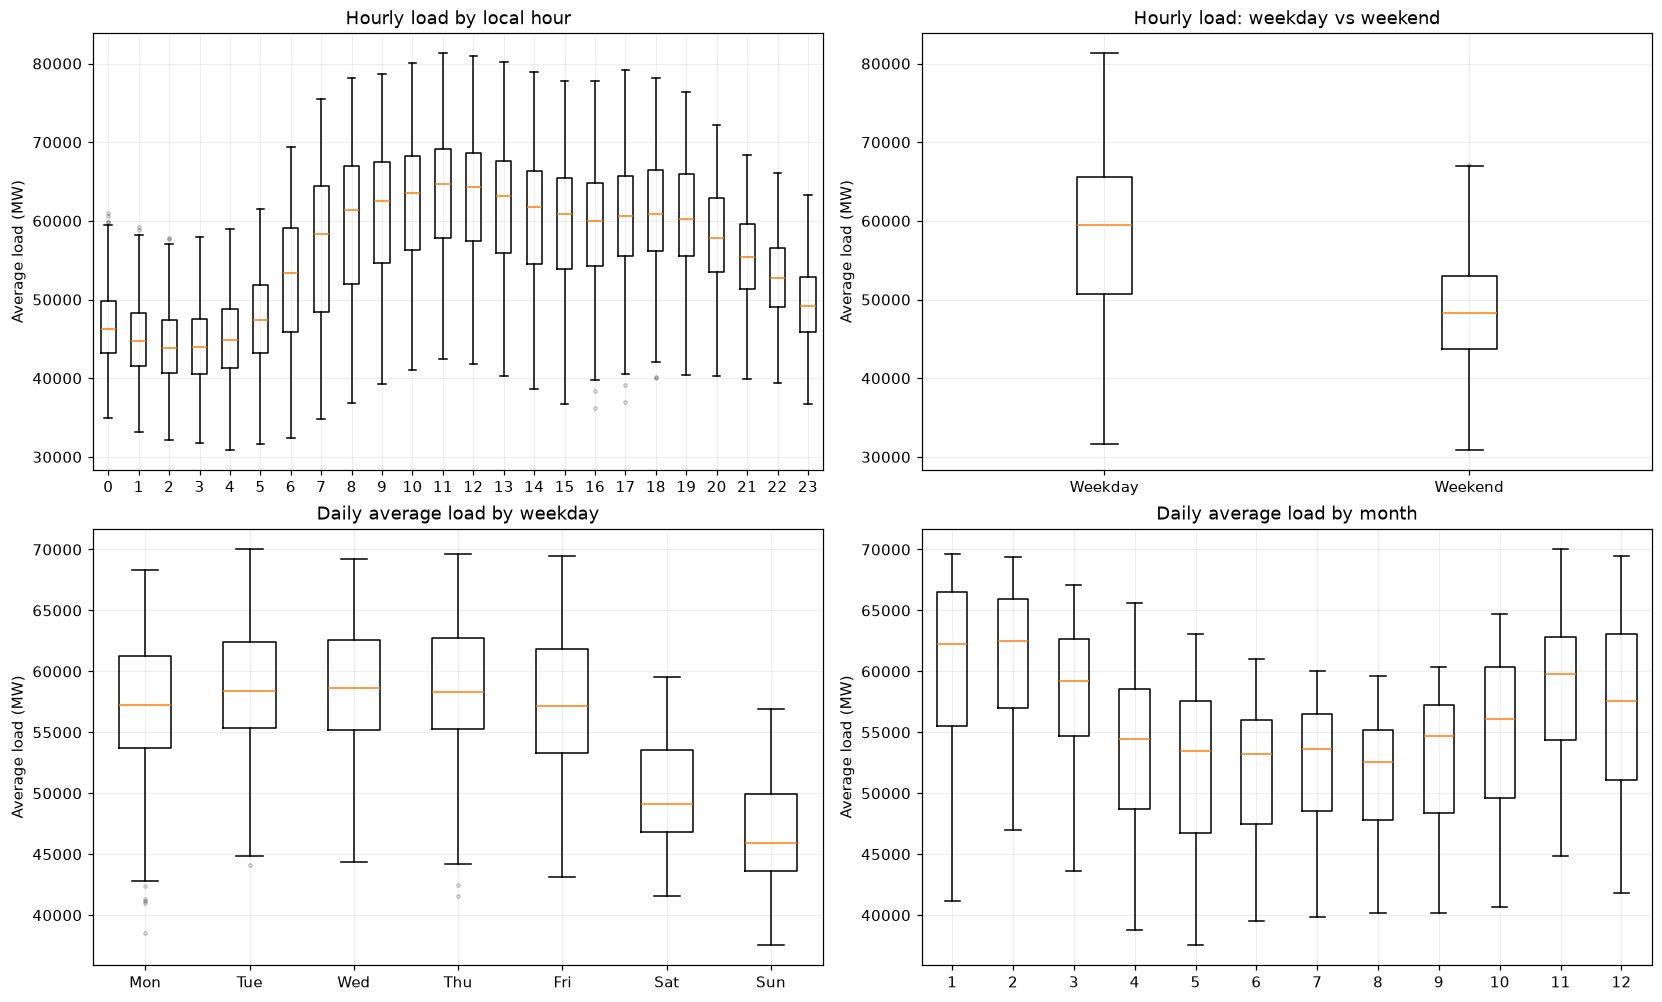

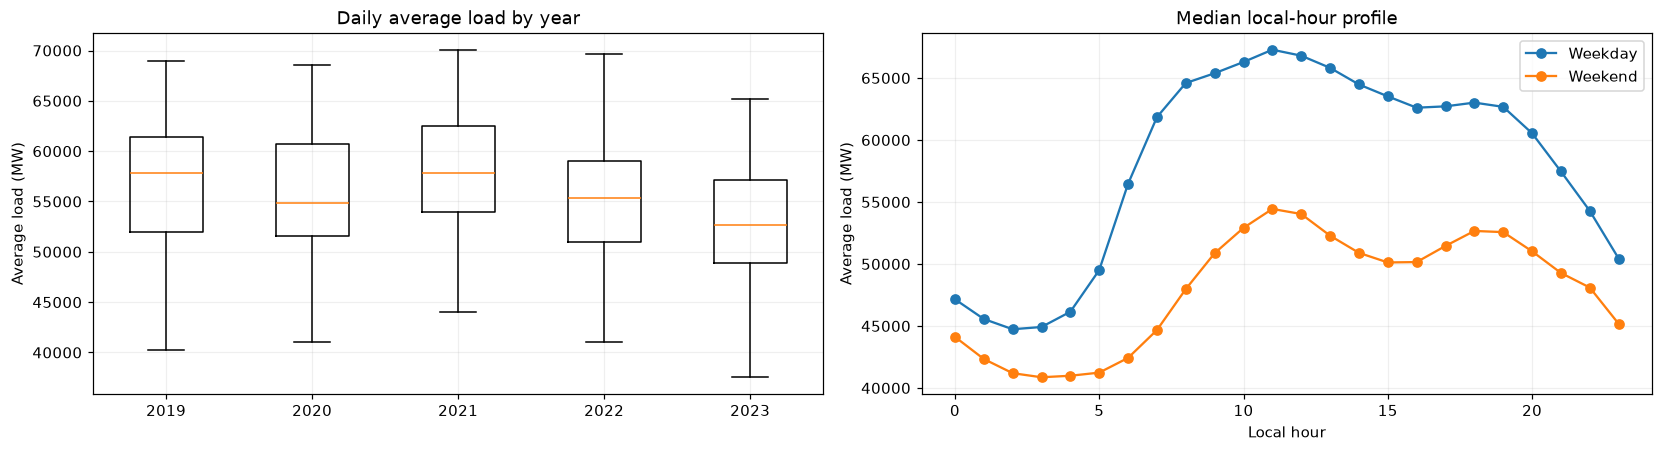

In [3]:
def calendar_boxplot(ax, frame, group, order, labels, title):
    samples = [frame.loc[frame[group].eq(value), 'average_load_mw'].to_numpy()
               for value in order]
    ax.boxplot(samples, tick_labels=labels, showfliers=True,
               flierprops={'markersize': 2, 'alpha': 0.25})
    ax.set(title=title, ylabel='Average load (MW)')

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
calendar_boxplot(axes[0, 0], hourly, 'hour', range(24), range(24), 'Hourly load by local hour')
calendar_boxplot(axes[0, 1], hourly, 'day_type', ['Weekday', 'Weekend'],
                 ['Weekday', 'Weekend'], 'Hourly load: weekday vs weekend')
calendar_boxplot(axes[1, 0], daily, 'weekday', range(7),
                 ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], 'Daily average load by weekday')
calendar_boxplot(axes[1, 1], daily, 'month', range(1, 13), range(1, 13),
                 'Daily average load by month')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
calendar_boxplot(axes[0], daily, 'year', range(2019, 2024), range(2019, 2024),
                 'Daily average load by year')
for kind, group in hourly.groupby('day_type'):
    axes[1].plot(group.groupby('hour')['average_load_mw'].median(), marker='o', label=kind)
axes[1].set(title='Median local-hour profile', xlabel='Local hour', ylabel='Average load (MW)')
axes[1].legend()
plt.show()

## Phase 3 — Rank the 20 largest changes

Two different questions:

1. **Adjacent change:** how much did consumption change from the previous physical hour or local calendar day? Gaps are excluded.
2. **Weekly change:** how different is it from the same German local hour/date seven days earlier? This is a calendar match, not a 168-row shift.

Weekly hourly comparisons exclude both repeated autumn local hours, and any observation whose reference hour is ambiguous. The first week also has no reference. Excluded comparisons remain NaN and are counted below.

Daily rankings use the change in **average MW**, while displaying original daily MWh too. This reduces false alarms caused purely by day length. It cannot account for weather or holidays.

In [4]:
rankings = {}
for resolution, frame in analysis.items():
    for method, score in [('adjacent', 'change_average_load_mw'),
                          ('weekly', 'week_change_average_load_mw')]:
        reference = ('previous_average_load_mw' if method == 'adjacent'
                     else 'week_reference_average_load_mw')
        valid = frame.dropna(subset=[score]).copy()
        ranked = valid.loc[valid[score].abs().nlargest(TOP_N).index,
                           ['start_local', 'consumption_mwh', 'interval_hours',
                            'average_load_mw', reference, score, 'day_type', 'weekday']].copy()
        ranked['absolute_change_mw'] = ranked[score].abs()
        rankings[(resolution, method)] = ranked
        print(f'{resolution} / {method}: {len(valid):,} comparable; '
              f'{frame[score].isna().sum():,} excluded; top {len(ranked)} below')
        display(ranked)

hourly / adjacent: 43,823 comparable; 1 excluded; top 20 below


,start_local,consumption_mwh,interval_hours,average_load_mw,previous_average_load_mw,change_average_load_mw,day_type,weekday,absolute_change_mw
7037,2019-10-21 06:00:00+02:00,57693.50,1.0,57693.50,47741.50,9952.00,Weekday,0,9952.00
6365,2019-09-23 06:00:00+02:00,57713.50,1.0,57713.50,47952.00,9761.50,Weekday,0,9761.50
6533,2019-09-30 06:00:00+02:00,60626.00,1.0,60626.00,50910.75,9715.25,Weekday,0,9715.25
6197,2019-09-16 06:00:00+02:00,56667.75,1.0,56667.75,47015.00,9652.75,Weekday,0,9652.75
15101,2020-09-21 06:00:00+02:00,53434.00,1.0,53434.00,43805.25,9628.75,Weekday,0,9628.75
25014,2021-11-08 06:00:00+01:00,61765.75,1.0,61765.75,52178.50,9587.25,Weekday,0,9587.25
6701,2019-10-07 06:00:00+02:00,57437.25,1.0,57437.25,47851.75,9585.50,Weekday,0,9585.50
7374,2019-11-04 06:00:00+01:00,58476.50,1.0,58476.50,48916.00,9560.50,Weekday,0,9560.50
7710,2019-11-18 06:00:00+01:00,61846.25,1.0,61846.25,52288.25,9558.00,Weekday,0,9558.00
24173,2021-10-04 06:00:00+02:00,56835.75,1.0,56835.75,47385.25,9450.50,Weekday,0,9450.50


hourly / weekly: 43,636 comparable; 188 excluded; top 20 below


,start_local,consumption_mwh,interval_hours,average_load_mw,week_reference_average_load_mw,week_change_average_load_mw,day_type,weekday,absolute_change_mw
176,2019-01-08 08:00:00+01:00,73450.50,1.0,73450.50,39575.25,33875.25,Weekday,1,33875.25
8936,2020-01-08 08:00:00+01:00,73452.00,1.0,73452.00,40177.75,33274.25,Weekday,2,33274.25
175,2019-01-08 07:00:00+01:00,71017.25,1.0,71017.25,38756.00,32261.25,Weekday,1,32261.25
177,2019-01-08 09:00:00+01:00,73559.00,1.0,73559.00,42119.25,31439.75,Weekday,1,31439.75
8935,2020-01-08 07:00:00+01:00,70538.75,1.0,70538.75,39464.25,31074.50,Weekday,2,31074.50
8937,2020-01-08 09:00:00+01:00,73429.75,1.0,73429.75,42374.00,31055.75,Weekday,2,31055.75
8938,2020-01-08 10:00:00+01:00,74463.00,1.0,74463.00,44553.00,29910.00,Weekday,2,29910.00
178,2019-01-08 10:00:00+01:00,74189.25,1.0,74189.25,44866.50,29322.75,Weekday,1,29322.75
8599,2019-12-25 07:00:00+01:00,38735.25,1.0,38735.25,67684.75,-28949.50,Weekday,2,28949.50
8939,2020-01-08 11:00:00+01:00,74708.00,1.0,74708.00,46662.25,28045.75,Weekday,2,28045.75


daily / adjacent: 1,825 comparable; 1 excluded; top 20 below


,start_local,consumption_mwh,interval_hours,average_load_mw,previous_average_load_mw,change_average_load_mw,day_type,weekday,absolute_change_mw
181,2019-07-01 00:00:00+02:00,1441602.00,24.0,60066.750000,45456.427083,14610.322917,Weekday,0,14610.322917
314,2019-11-11 00:00:00+01:00,1525379.00,24.0,63557.458333,49462.822917,14094.635417,Weekday,0,14094.635417
741,2021-01-11 00:00:00+01:00,1630217.25,24.0,67925.718750,53863.635417,14062.083333,Weekday,0,14062.083333
174,2019-06-24 00:00:00+02:00,1384408.75,24.0,57683.697917,43679.468750,14004.229167,Weekday,0,14004.229167
1126,2022-01-31 00:00:00+01:00,1620269.50,24.0,67511.229167,53725.968750,13785.260417,Weekday,0,13785.260417
909,2021-06-28 00:00:00+02:00,1406498.25,24.0,58604.093750,44842.864583,13761.229167,Weekday,0,13761.229167
496,2020-05-11 00:00:00+02:00,1339857.75,24.0,55827.406250,42386.562500,13440.843750,Weekday,0,13440.843750
20,2019-01-21 00:00:00+01:00,1600868.75,24.0,66702.864583,53327.614583,13375.250000,Weekday,0,13375.250000
139,2019-05-20 00:00:00+02:00,1393622.25,24.0,58067.593750,44708.854167,13358.739583,Weekday,0,13358.739583
112,2019-04-23 00:00:00+02:00,1337117.75,24.0,55713.239583,42355.958333,13357.281250,Weekday,1,13357.281250


daily / weekly: 1,819 comparable; 7 excluded; top 20 below


,start_local,consumption_mwh,interval_hours,average_load_mw,week_reference_average_load_mw,week_change_average_load_mw,day_type,weekday,absolute_change_mw
7,2019-01-08 00:00:00+01:00,1605658.75,24.0,66902.447917,45713.281250,21189.166667,Weekday,1,21189.166667
372,2020-01-08 00:00:00+01:00,1571399.50,24.0,65474.979167,45429.822917,20045.156250,Weekday,2,20045.156250
1455,2022-12-26 00:00:00+01:00,1047961.75,24.0,43665.072917,61612.239583,-17947.166667,Weekday,0,17947.166667
358,2019-12-25 00:00:00+01:00,1064150.00,24.0,44339.583333,61784.885417,-17445.302083,Weekday,2,17445.302083
738,2021-01-08 00:00:00+01:00,1503616.25,24.0,62650.677083,45789.229167,16861.447917,Weekday,4,16861.447917
359,2019-12-26 00:00:00+01:00,1060206.25,24.0,44175.260417,60940.104167,-16764.843750,Weekday,3,16764.843750
111,2019-04-22 00:00:00+02:00,1016543.00,24.0,42355.958333,58598.166667,-16242.208333,Weekday,0,16242.208333
1819,2023-12-25 00:00:00+01:00,1059197.00,24.0,44133.208333,60292.697917,-16159.489583,Weekday,0,16159.489583
1820,2023-12-26 00:00:00+01:00,1077192.25,24.0,44883.010417,60817.322917,-15934.312500,Weekday,1,15934.312500
118,2019-04-29 00:00:00+02:00,1391408.75,24.0,57975.364583,42355.958333,15619.406250,Weekday,0,15619.406250


## Phase 4 — Flag unusually high/low values within smaller groups

Applying the 1.5-IQR (standard choice) rule within **year + month + weekday/weekend**, adding **local hour** for hourly data. This compares more similar observations than the global rule. Daily values are average MW.

Groups with fewer than eight observations or zero IQR are ignored. Small groups and holidays can still create misleading flags. (need external data e.g. weather, public holiday calendar to relate with this)

In [5]:
iqr_summary = []
for resolution, frame in analysis.items():
    flags = frame.loc[frame['iqr_candidate']].copy()
    iqr_summary.append({'dataset': resolution, 'observations': len(frame),
        'screened': int(frame['iqr_screened'].sum()),
        'not_assessed': int((~frame['iqr_screened']).sum()), 'candidates': len(flags)})
    flags['distance_outside_bounds_mw'] = np.maximum(
        flags['iqr_lower_mw'] - flags['average_load_mw'],
        flags['average_load_mw'] - flags['iqr_upper_mw'])
    print(f'{resolution}: largest distances outside contextual IQR bounds')
    display(flags.nlargest(TOP_N, 'distance_outside_bounds_mw')[
        ['start_local', 'consumption_mwh', 'average_load_mw', 'day_type',
         'group_count', 'iqr_lower_mw', 'iqr_upper_mw', 'distance_outside_bounds_mw']])
iqr_summary = pd.DataFrame(iqr_summary)
display(iqr_summary)

hourly: largest distances outside contextual IQR bounds


,start_local,consumption_mwh,average_load_mw,day_type,group_count,iqr_lower_mw,iqr_upper_mw,distance_outside_bounds_mw
8,2019-01-01 08:00:00+01:00,39575.25,39575.25,Weekday,23,69710.87500,76864.87500,30135.62500
7,2019-01-01 07:00:00+01:00,38756.00,38756.00,Weekday,23,66657.87500,75158.87500,27901.87500
9,2019-01-01 09:00:00+01:00,42119.25,42119.25,Weekday,23,69029.56250,77916.06250,26910.31250
8768,2020-01-01 08:00:00+01:00,40177.75,40177.75,Weekday,23,66782.50000,77755.50000,26604.75000
8769,2020-01-01 09:00:00+01:00,42374.00,42374.00,Weekday,23,67509.81250,77195.31250,25135.81250
8767,2020-01-01 07:00:00+01:00,39464.25,39464.25,Weekday,23,63539.87500,76096.87500,24075.62500
10,2019-01-01 10:00:00+01:00,44866.50,44866.50,Weekday,23,68751.56250,79335.06250,23885.06250
8770,2020-01-01 10:00:00+01:00,44553.00,44553.00,Weekday,23,67540.81250,77972.31250,22987.81250
6,2019-01-01 06:00:00+01:00,38047.50,38047.50,Weekday,23,59774.12500,69120.12500,21726.62500
8771,2020-01-01 11:00:00+01:00,46662.25,46662.25,Weekday,23,67766.62500,78327.62500,21104.37500


daily: largest distances outside contextual IQR bounds


,start_local,consumption_mwh,average_load_mw,day_type,group_count,iqr_lower_mw,iqr_upper_mw,distance_outside_bounds_mw
0,2019-01-01 00:00:00+01:00,1097118.75,45713.281250,Weekday,23,61477.210938,71333.773438,15763.929688
365,2020-01-01 00:00:00+01:00,1090315.75,45429.822917,Weekday,23,60113.583333,70041.125000,14683.760417
731,2021-01-01 00:00:00+01:00,1098941.50,45789.229167,Weekday,21,57309.333333,73749.750000,11520.104167
111,2019-04-22 00:00:00+02:00,1016543.00,42355.958333,Weekday,22,53119.572917,64716.406250,10763.614583
160,2019-06-10 00:00:00+02:00,1027291.50,42803.812500,Weekday,20,52521.273438,62546.127604,9717.460938
1609,2023-05-29 00:00:00+02:00,924870.00,38536.250000,Weekday,23,47936.375000,57175.000000,9400.125000
1252,2022-06-06 00:00:00+02:00,1052948.50,43872.854167,Weekday,22,53157.329427,57029.402344,9284.475260
1560,2023-04-10 00:00:00+02:00,991279.75,41303.322917,Weekday,20,50254.721354,57809.783854,8951.398438
517,2020-06-01 00:00:00+02:00,983914.50,40996.437500,Weekday,22,49892.563802,57010.157552,8896.126302
275,2019-10-03 00:00:00+02:00,1146045.00,47751.875000,Weekday,23,56457.304688,63982.492188,8705.429688


,dataset,observations,screened,not_assessed,candidates
0,hourly,43824,43803,21,2171
1,daily,1826,1826,0,87
